# Recommandation de films

**Objectif** : proposer à un spectateur 5 films proches d'un film qu'il a aimé.

**Méthode** : les plus proches voisins (`NearestNeighbors`). Chaque film est décrit par des colonnes chiffrées ; le modèle recommande les films dont la description est la plus proche.

**Données** : `film_complet.csv`, le catalogue commun préparé dans `preparation_catalogue_final`.

## 1. Imports et chargement des données

In [55]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

data = pd.read_csv("../data/propre/film_complet.csv")
print(data.shape)   # attendu : (3508, 16)
data.head()

(3508, 16)


,id_imdb,titre,titre_original,titre_principal,annee,duree_min,genres,note_imdb,nb_votes_imdb,popularite_tmdb,langue_originale,pays_production,societes_production,resume,mots_cles,affiche
0,tt0057485,Assassination in Rome,Il segreto del vestito rosso,Assassination in Rome,1965.0,110.0,"Comedy,Crime,Mystery",5.4,249.0,4.513,en,"France, Italy, Spain","Apo Film, Midega Film, Dicifrance","In this crime-thriller, Rome proves to be an u...",eurospy,/14NaoHCRdvScUzYbNPksNVbOEgb.jpg
1,tt0057615,Umorismo in nero,Umorismo in nero,Umorismo in nero,1965.0,93.0,Comedy,5.2,53.0,1.223,es,"Spain, Italy, France","Época Films, Sagittario Film, Lux Compagnie Ci...",NaN,dark comedy,/vMsXGeyCP6P4aGcVJRUAQAQW4kx.jpg
2,tt0057841,Memories of My Childhood,Amintiri din copilarie,Memories of My Childhood,1965.0,72.0,"Adventure,Biography,Comedy",8.0,643.0,0.618,ro,Romania,Studioul Cinematografic București,"Based on Ion Creanga's book, the story of a ch...",NaN,/cOxzgvSSms746hmX4i6SccMDfqK.jpg
3,tt0057965,Les Copains,Les copains,Les copains,1965.0,95.0,Comedy,6.2,293.0,1.288,fr,France,Les Productions de la Guéville,NaN,NaN,/kmgfML9nSXFhismrlMgEgzFJG3N.jpg
4,tt0057967,Le Corniaud,Le corniaud,The Sucker,1965.0,111.0,"Adventure,Comedy,Crime",7.3,9206.0,11.899,fr,"Spain, France, Italy","Les Films Corona, Explorer Film '58","In this Frenco-Italian gangster parody, a shop...","france, paris, france, drug smuggling, diamond...",/xkCGWJ0GYx3nK2PoFZdpl6L49q1.jpg


## 2. Les colonnes utilisées

Pour dire que deux films se ressemblent, on compare :
- leur **genre** (comédie, action, drame…) ;
- leur **année** de sortie ;
- leur **durée** ;
- leur **note** IMDb ;
- leur **nombre de votes** (pour savoir si le film est connu ou confidentiel) ;
- leur **langue** (français ou non).

On n'a pas gardé la popularité TMDB : elle mesure, comme le nombre de votes, si un film est connu. La garder aurait compté ce critère deux fois.

On vérifie ensuite qu'il ne manque aucune valeur dans ces colonnes.

In [56]:
colonnes_num = ["annee", "duree_min", "note_imdb", "nb_votes_imdb"]

# Vérifier les valeurs manquantes des colonnes utilisées
data[colonnes_num + ["genres", "langue_originale"]].isna().sum()

annee               0
duree_min           8
note_imdb           0
nb_votes_imdb       0
genres              0
langue_originale    0
dtype: int64

Il manque la durée de 8 films. On leur donne la durée médiane du catalogue : c'est une valeur réaliste, peu influencée par les films très longs ou très courts.

In [57]:
data["duree_min"] = data["duree_min"].fillna(data["duree_min"].median())

# Vérification : plus aucune durée manquante
data["duree_min"].isna().sum()

np.int64(0)

## 3. Préparer les données pour le modèle

Le modèle ne comprend que les chiffres. On transforme donc :
- **les genres** : une colonne par genre, avec 1 si le film a ce genre, 0 sinon. Par exemple, une comédie d'action aura 1 dans « Action » et 1 dans « Comedy » ;
- **la langue** : une colonne « francais », avec 1 si le film est en français, 0 sinon.

On regroupe ensuite tout dans un tableau `X` : c'est ce que le modèle va utiliser pour comparer les films.

In [58]:
# Une colonne par genre (1 = le film a ce genre, 0 = non)
genres = data["genres"].str.get_dummies(sep=",")

# Le tableau X : colonnes chiffrées + genres
X = pd.concat([data[colonnes_num], genres], axis=1)

# Film en français : 1 = oui, 0 = non
X["francais"] = (data["langue_originale"] == "fr").astype(int)

print(X.shape)   # attendu : (3508, 26)
X.head()

(3508, 26)


,annee,duree_min,note_imdb,nb_votes_imdb,Action,Adventure,Animation,Biography,Comedy,Crime,...,Music,Musical,Mystery,Romance,Sci-Fi,Sport,Thriller,War,Western,francais
0,1965.0,110.0,5.4,249.0,0,0,0,0,1,1,...,0,0,1,0,0,0,0,0,0,0
1,1965.0,93.0,5.2,53.0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1965.0,72.0,8.0,643.0,0,1,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1965.0,95.0,6.2,293.0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
4,1965.0,111.0,7.3,9206.0,0,1,0,0,1,1,...,0,0,0,0,0,0,0,0,0,1


## 4. Vérifications avant le modèle

### Les colonnes se répètent-elles ?
Si deux colonnes disent la même chose, ce critère compterait deux fois dans la comparaison des films. La carte ci-dessous mesure le lien entre les colonnes chiffrées : plus le chiffre est proche de 1 (ou de -1), plus elles se ressemblent.

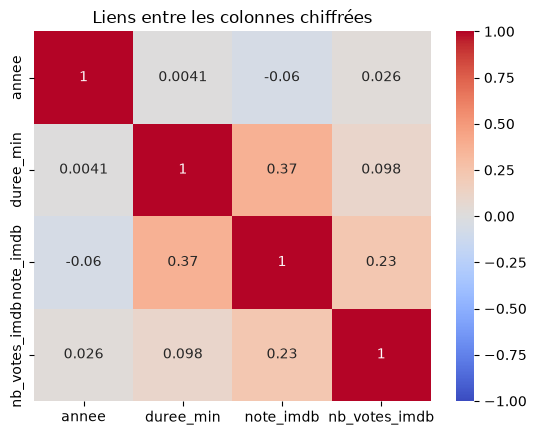

In [59]:
sns.heatmap(data[colonnes_num].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Liens entre les colonnes chiffrées")
plt.show()

Le lien le plus fort est de 0,37 (durée et note : les films longs sont un peu mieux notés). C'est faible : chaque colonne apporte une information différente, on les garde toutes.

### Mettre les colonnes à la même échelle
Les colonnes n'ont pas les mêmes ordres de grandeur : une note va de 1 à 10, alors que le nombre de votes va de quelques milliers à plus de 2 millions. Sans correction, le nombre de votes écraserait tout le reste dans la comparaison.

On fait deux choses :
1. **le logarithme sur le nombre de votes** : il réduit les écarts énormes entre les films très connus et les autres ;
2. **la mise à l'échelle** (`StandardScaler`) : toutes les colonnes chiffrées sont ramenées à une échelle comparable.

Les genres et la langue valent déjà 0 ou 1 : on n'y touche pas.

In [60]:
# 1. Réduire les écarts du nombre de votes
X["nb_votes_imdb"] = np.log1p(X["nb_votes_imdb"])

# 2. Mettre les colonnes chiffrées à la même échelle
scaler = StandardScaler().set_output(transform="pandas")
X[colonnes_num] = scaler.fit_transform(X[colonnes_num])

X.head()

,annee,duree_min,note_imdb,nb_votes_imdb,Action,Adventure,Animation,Biography,Comedy,Crime,...,Music,Musical,Mystery,Romance,Sci-Fi,Sport,Thriller,War,Western,francais
0,-2.123627,0.498240,-1.095649,-0.706094,0,0,0,0,1,1,...,0,0,1,0,0,0,0,0,0,0
1,-2.123627,-0.373289,-1.311815,-1.455547,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,-2.123627,-1.449885,1.714507,-0.243340,0,1,0,1,1,0,...,0,0,0,0,0,0,0,0,0,0
3,-2.123627,-0.270756,-0.230986,-0.626810,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
4,-2.123627,0.549507,0.957927,1.057535,0,1,0,0,1,1,...,0,0,0,0,0,0,0,0,0,1


## 5. Le modèle

On utilise `NearestNeighbors` (les plus proches voisins). Pour chaque film, il mesure la distance avec tous les autres films du catalogue : plus la distance est petite, plus les films se ressemblent.

Il n'y a pas de bonne réponse à prédire : le modèle apprend simplement le catalogue complet, pour pouvoir y chercher les films les plus proches.

In [61]:
neighbors = NearestNeighbors(n_neighbors=6, metric="euclidean")
neighbors.fit(X)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",6
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


## 6. Recommander des films

La fonction `recommander` :
1. retrouve le film demandé dans le catalogue ;
2. cherche ses voisins les plus proches ;
3. retire le film lui-même et affiche les 5 autres.

⚠️ Le titre doit être écrit exactement comme dans le catalogue.

In [62]:
def recommander(titre, nb_films=5):
    # 1. Trouver la position du film dans le catalogue
    position = data[data["titre"] == titre].index[0]

    # 2. Chercher ses voisins (+1, car le film est son propre voisin)
    distances, indices = neighbors.kneighbors(X.iloc[[position]], n_neighbors=nb_films + 1)

    # 3. Retirer le film lui-même et afficher les autres
    voisins = indices[0][1:]
    return data.iloc[voisins][["titre", "annee", "genres", "note_imdb", "langue_originale"]]

## 7. Tests

On teste des films très différents : récent ou ancien, connu ou confidentiel, français ou étranger. Pour chaque test, on vérifie que les recommandations ont du sens (genre, époque, note, langue).

In [63]:
recommander("Deadpool")

,titre,annee,genres,note_imdb,langue_originale
2527,Les Gardiens de la Galaxie,2014.0,"Action,Adventure,Comedy",8.0,en
1723,Hot Fuzz,2007.0,"Action,Comedy,Mystery",7.8,en
2637,The Grand Budapest Hotel,2014.0,"Comedy,Drama",8.1,en
1633,Shaun of the Dead,2004.0,"Comedy,Horror",7.8,en
1266,Snatch : Tu braques ou tu raques,2000.0,"Comedy,Crime",8.2,en


*Deadpool* (comédie d'action récente) : le modèle propose d'autres comédies d'action récentes et bien notées (*Les Gardiens de la Galaxie*, *Hot Fuzz*…).

In [64]:
recommander("Le Corniaud")

,titre,annee,genres,note_imdb,langue_originale
132,Le Cerveau,1969.0,"Adventure,Comedy,Crime",6.8,fr
182,"L'aventure, c'est l'aventure",1972.0,"Adventure,Comedy,Crime",6.9,fr
17,Fantômas se déchaîne,1965.0,"Adventure,Comedy,Crime",6.8,fr
60,Fantômas contre Scotland Yard,1967.0,"Adventure,Comedy,Crime",6.7,fr
165,Le Gendarme en balade,1970.0,"Comedy,Crime",6.5,fr


*Le Corniaud* : uniquement des comédies françaises des années 60-70, dont plusieurs avec Louis de Funès. Le modèle ne connaît pas les acteurs : il les retrouve grâce à l'époque, au genre et à la langue.

In [65]:
recommander("Intouchables")

,titre,annee,genres,note_imdb,langue_originale
2637,The Grand Budapest Hotel,2014.0,"Comedy,Drama",8.1,en
1012,The Truman Show,1998.0,"Comedy,Drama",8.2,en
3117,3 Billboards : Les Panneaux de la vengeance,2017.0,"Comedy,Crime,Drama",8.1,en
2372,The Artist,2011.0,"Comedy,Drama,Romance",7.8,fr
1284,Le Fabuleux Destin d'Amélie Poulain,2001.0,"Comedy,Romance",8.2,fr


*Intouchables* : des comédies dramatiques très bien notées, dont deux films français (*The Artist*, *Amélie Poulain*). La langue rapproche les films français, sans pour autant écarter les films étrangers.

## 8. Démarche suivie

Le modèle a été construit par essais successifs. À chaque étape, nous avons testé plusieurs films et vérifié la cohérence des recommandations.

**Version 1 : colonnes brutes**
Pour *Deadpool*, le modèle recommandait des films Pixar pour enfants. Le nombre de votes, qui va de quelques milliers à plus de 2 millions, dominait le calcul : le modèle rapprochait surtout les films très connus, quel que soit leur genre.

**Version 2 : logarithme sur le nombre de votes**
Les écarts sont réduits et les résultats s'améliorent. Mais la popularité TMDB mesurait elle aussi la notoriété, qui comptait donc deux fois.

**Version 3 : retrait de la popularité TMDB**
Les recommandations suivent désormais le genre et l'époque. Pour *Deadpool*, *Hot Fuzz* (comédie d'action) remplace *Toy Story 3*.

**Version 4 : ajout de la langue**
Le projet étant destiné à un cinéma français, nous avons ajouté une colonne indiquant si le film est en français. Les films français sont un peu plus souvent proposés entre eux, sans que les films étrangers soient écartés.

## 9. Limites

- **Le titre doit être exact** : une faute de frappe empêche de trouver le film.
- **Le contenu des films n'est pas utilisé** : le modèle compare le genre, l'année, la durée, la note et la langue, mais pas le résumé. Exploiter le résumé serait une piste d'amélioration.